<a href="https://colab.research.google.com/github/Ayesh2002/ml-student-dropout/blob/RF/02_random_forest.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

## 01. Import libraries

In [1]:
# Data handling and visualisation
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import sklearn

# Data splitting and model validation
from sklearn.model_selection import (
    train_test_split,
    StratifiedKFold,
    cross_validate,
    GridSearchCV
)

# Preprocessing
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline

# Random Forest model
from sklearn.ensemble import RandomForestClassifier

# Evaluation metrics
from sklearn.metrics import (
    accuracy_score,
    f1_score,
    balanced_accuracy_score,
    classification_report,
    ConfusionMatrixDisplay
)

# Fixed seed for reproducibility
SEED = 42

print("Libraries imported successfully.")
print("scikit-learn version:", sklearn.__version__)

Libraries imported successfully.
scikit-learn version: 1.6.1


##2. Load and preview the dataset

In [2]:
# Dataset URL
DATA_URL = (
    "https://raw.githubusercontent.com/Ayesh2002/ml-student-dropout/"
    "5d932c6ff712451a084f57a6dd2df39fb6277890/data/student_dropout_academic_.csv"
)

# Load the dataset
df = pd.read_csv(DATA_URL)

# Display its dimensions
print("Dataset shape:", df.shape)

# Preview the first five records
df.head()

Dataset shape: (4424, 37)


,Marital status,Application mode,Application order,Course,Daytime/evening attendance,Previous qualification,Previous qualification (grade),Nationality,Mother's qualification,Father's qualification,...,Curricular units 2nd sem (credited),Curricular units 2nd sem (enrolled),Curricular units 2nd sem (evaluations),Curricular units 2nd sem (approved),Curricular units 2nd sem (grade),Curricular units 2nd sem (without evaluations),Unemployment rate,Inflation rate,GDP,Target
0,1,17,5,171,1,1,122.0,1,19,12,...,0,0,0,0,0.000000,0,10.8,1.4,1.74,Dropout
1,1,15,1,9254,1,1,160.0,1,1,3,...,0,6,6,6,13.666667,0,13.9,-0.3,0.79,Graduate
2,1,1,5,9070,1,1,122.0,1,37,37,...,0,6,0,0,0.000000,0,10.8,1.4,1.74,Dropout
3,1,17,2,9773,1,1,122.0,1,38,37,...,0,6,10,5,12.400000,0,9.4,-0.8,-3.12,Graduate
4,2,39,1,8014,0,1,100.0,1,37,38,...,0,6,6,6,13.000000,0,13.9,-0.3,0.79,Graduate


##3. Check dataset structure and quality

In [3]:
# Inspect column names and data types
df.info()

# Check missing values
print("\nTotal missing values:", df.isna().sum().sum())

# Check duplicate records
print("Duplicate records:", df.duplicated().sum())

# Check the number of students in each target class
print("\nTarget class distribution:")
print(df["Target"].value_counts())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 4424 entries, 0 to 4423
Data columns (total 37 columns):
 #   Column                                          Non-Null Count  Dtype  
---  ------                                          --------------  -----  
 0   Marital status                                  4424 non-null   int64  
 1   Application mode                                4424 non-null   int64  
 2   Application order                               4424 non-null   int64  
 3   Course                                          4424 non-null   int64  
 4   Daytime/evening attendance                      4424 non-null   int64  
 5   Previous qualification                          4424 non-null   int64  
 6   Previous qualification (grade)                  4424 non-null   float64
 7   Nationality                                     4424 non-null   int64  
 8   Mother's qualification                          4424 non-null   int64  
 9   Father's qualification                   

##4. Separate the target and split the data

In [4]:
# Separate input features and target
X = df.drop(columns="Target").copy()
y = df["Target"].copy()

# Split while keeping similar class proportions
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    stratify=y,
    random_state=SEED
)

print("Training data shape:", X_train.shape)
print("Test data shape:", X_test.shape)

Training data shape: (3539, 36)
Test data shape: (885, 36)


##5. EDA: Explore the training class distribution

          Students  Percentage
Target                        
Graduate      1767       49.93
Dropout       1137       32.13
Enrolled       635       17.94


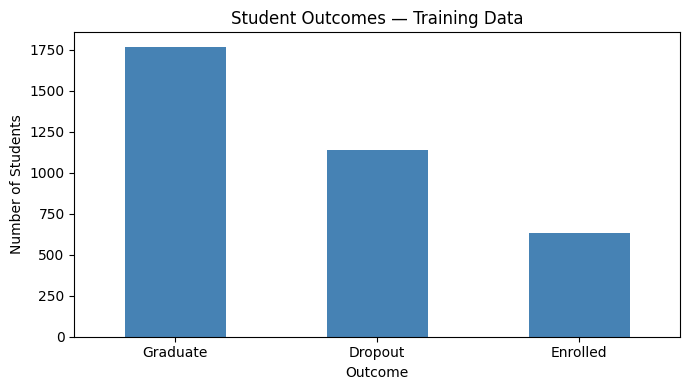

In [5]:
# Summarise the training target classes
class_counts = y_train.value_counts()

class_summary = pd.DataFrame({
    "Students": class_counts,
    "Percentage": (class_counts / len(y_train) * 100).round(2)
})

print(class_summary)

# Plot the class distribution
class_counts.plot(
    kind="bar",
    figsize=(7, 4),
    color="steelblue",
    rot=0
)

plt.title("Student Outcomes — Training Data")
plt.xlabel("Outcome")
plt.ylabel("Number of Students")
plt.tight_layout()
plt.show()

EDA: Explore numeric feature distributions

                                      count    mean    std   min     25%  \
Age at enrollment                    3539.0   23.25   7.61  17.0   19.00   
Admission grade                      3539.0  126.88  14.53  95.0  117.80   
Curricular units 1st sem (grade)     3539.0   10.62   4.87   0.0   11.00   
Curricular units 1st sem (approved)  3539.0    4.70   3.10   0.0    3.00   
Curricular units 2nd sem (grade)     3539.0   10.20   5.24   0.0   10.78   
Curricular units 2nd sem (approved)  3539.0    4.43   3.03   0.0    2.00   

                                        50%     75%     max  
Age at enrollment                     20.00   25.00   70.00  
Admission grade                      126.00  134.90  190.00  
Curricular units 1st sem (grade)      12.32   13.40   18.88  
Curricular units 1st sem (approved)    5.00    6.00   26.00  
Curricular units 2nd sem (grade)      12.20   13.33   18.57  
Curricular units 2nd sem (approved)    5.00    6.00   20.00  


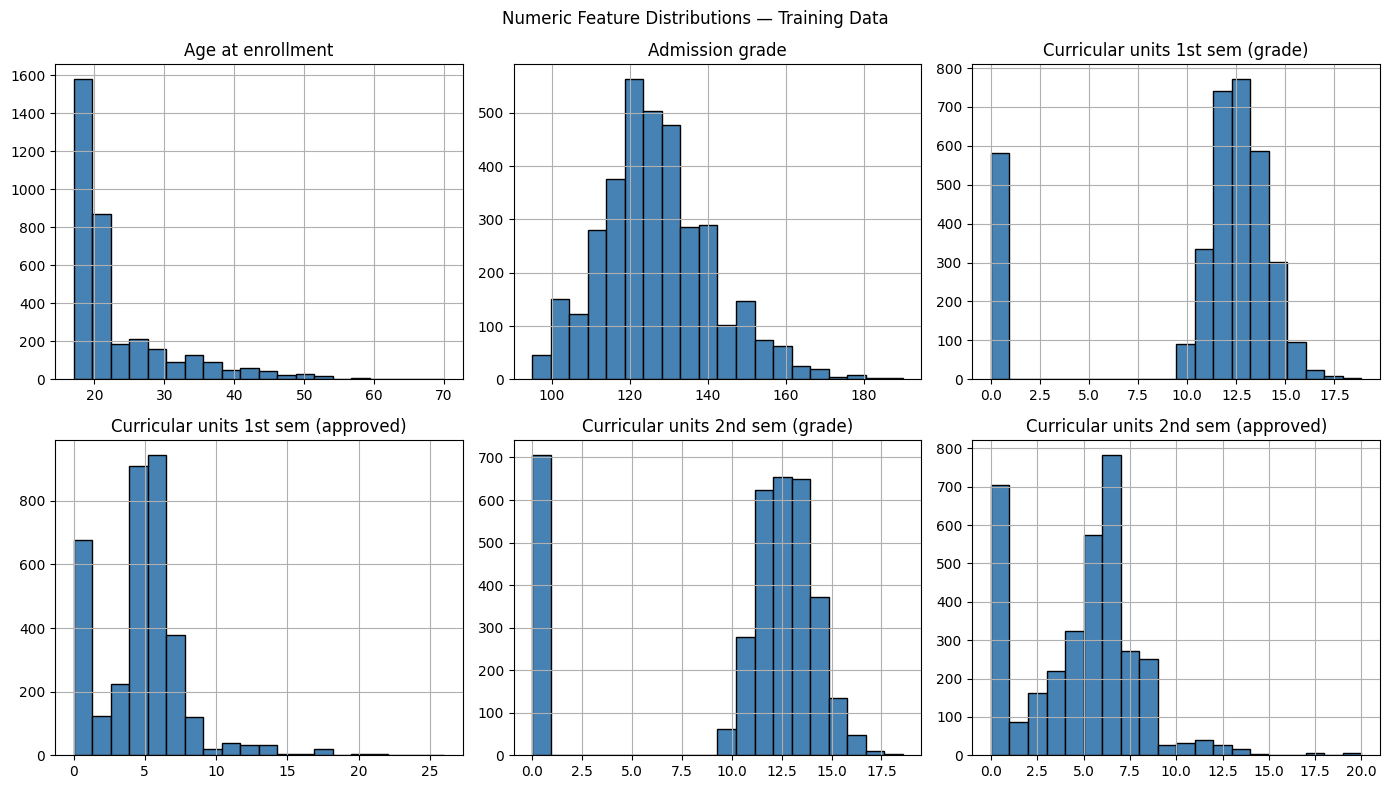

In [6]:
# Numeric features to explore
numeric_eda_cols = [
    "Age at enrollment",
    "Admission grade",
    "Curricular units 1st sem (grade)",
    "Curricular units 1st sem (approved)",
    "Curricular units 2nd sem (grade)",
    "Curricular units 2nd sem (approved)"
]

# Summary statistics from training data
print(X_train[numeric_eda_cols].describe().T.round(2))

# Plot the distributions
X_train[numeric_eda_cols].hist(
    bins=20,
    figsize=(14, 8),
    layout=(2, 3),
    color="steelblue",
    edgecolor="black"
)

plt.suptitle("Numeric Feature Distributions — Training Data")
plt.tight_layout()
plt.show()

Compare numeric features across outcomes

          Age at enrollment  Admission grade  \
Target                                         
Dropout                23.0            123.3   
Enrolled               20.0            123.9   
Graduate               19.0            127.3   

          Curricular units 1st sem (grade)  \
Target                                       
Dropout                              10.83   
Enrolled                             12.00   
Graduate                             13.00   

          Curricular units 1st sem (approved)  \
Target                                          
Dropout                                   2.0   
Enrolled                                  5.0   
Graduate                                  6.0   

          Curricular units 2nd sem (grade)  \
Target                                       
Dropout                                0.0   
Enrolled                              12.0   
Graduate                              13.0   

          Curricular units 2nd sem (approved)  
Tar

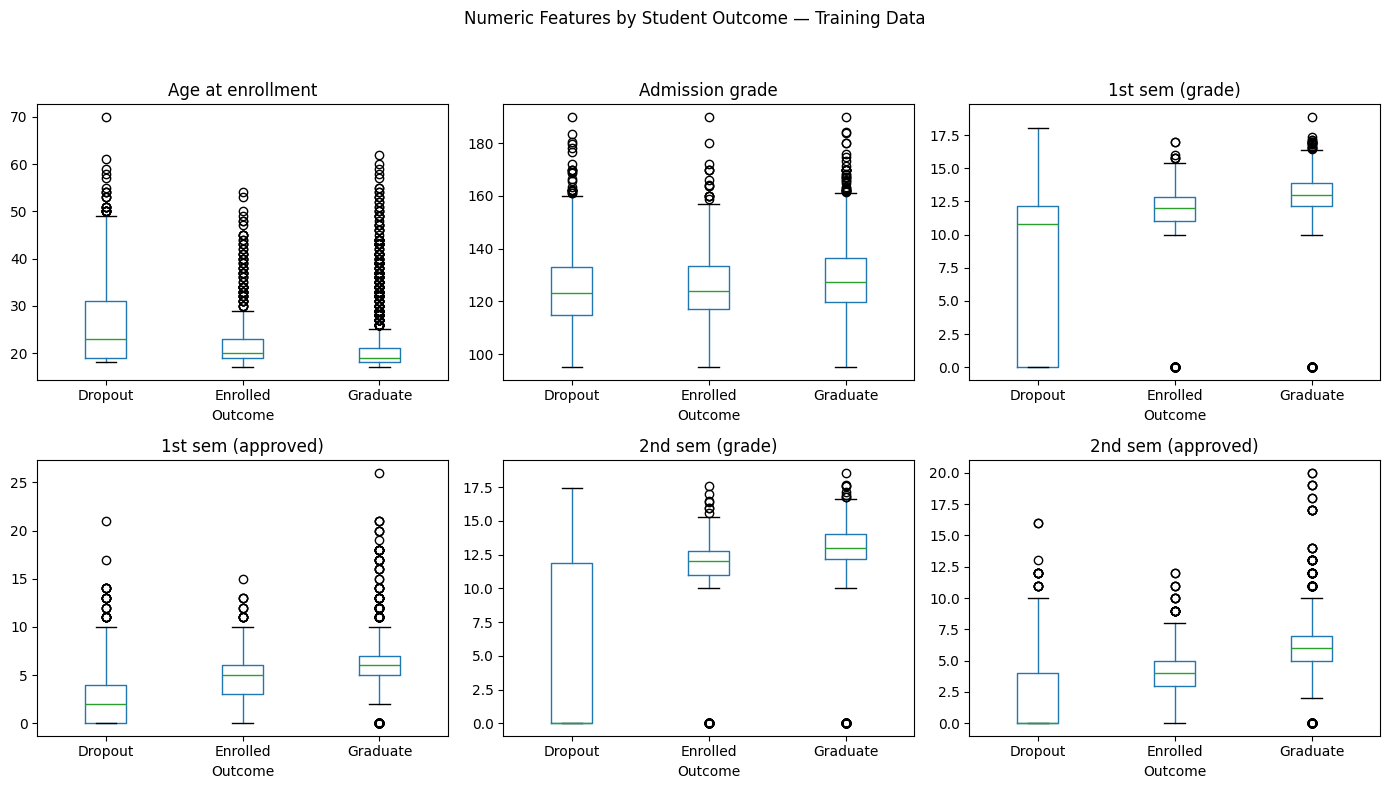

In [7]:
# Combine training features and outcomes for EDA
eda_train = X_train.copy()
eda_train["Target"] = y_train

# Compare median values across outcomes
print(
    eda_train.groupby("Target")[numeric_eda_cols]
    .median()
    .round(2)
)

# Draw boxplots for each numeric feature
fig, axes = plt.subplots(2, 3, figsize=(14, 8))

for column, ax in zip(numeric_eda_cols, axes.flat):
    eda_train.boxplot(
        column=column,
        by="Target",
        ax=ax,
        grid=False
    )
    ax.set_title(column.replace("Curricular units ", ""))
    ax.set_xlabel("Outcome")

fig.suptitle("Numeric Features by Student Outcome — Training Data")
fig.tight_layout(rect=[0, 0, 1, 0.95])
plt.show()

Explore categorical features


Course
Target  Students  Dropout (%)  Enrolled (%)  Graduate (%)
Course                                                   
33            10         70.0          20.0          10.0
171          175         38.3          15.4          46.3
8014         165         32.1          10.9          57.0
9003         171         39.2          18.1          42.7
9070         174         22.4          18.4          59.2
9085         277         28.5          22.7          48.7
9119         133         51.1          39.8           9.0
9130         115         55.7          13.9          30.4
9147         302         36.1          30.1          33.8
9238         291         18.9          10.3          70.8
9254         198         39.4          16.2          44.4
9500         607         14.8          13.7          71.5
9556          66         36.4          19.7          43.9
9670         213         32.9          16.9          50.2
9773         267         30.7          10.9          58.4
9853  

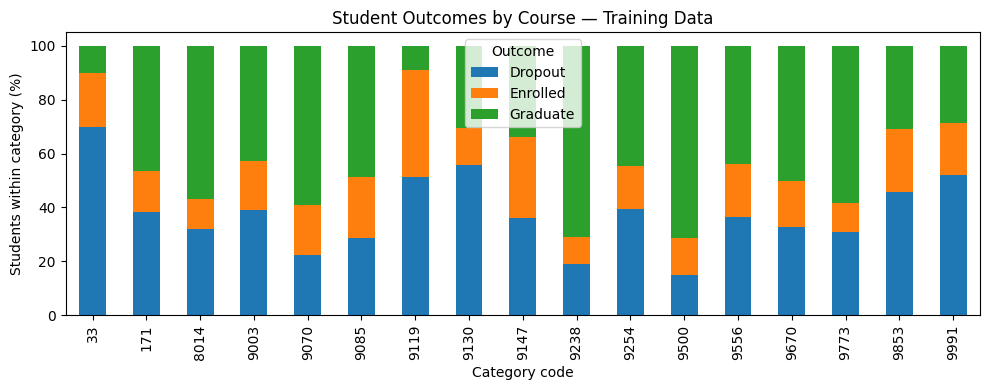


Application mode
Target            Students  Dropout (%)  Enrolled (%)  Graduate (%)
Application mode                                                   
1                     1364         19.6          17.0          63.4
2                        3         66.7           0.0          33.3
5                       15         13.3          53.3          33.3
7                      109         62.4           5.5          32.1
10                      10         30.0           0.0          70.0
15                      24          8.3          29.2          62.5
16                      31          9.7          22.6          67.7
17                     701         29.8          18.5          51.6
18                      98         38.8          10.2          51.0
26                       1        100.0           0.0           0.0
27                       1        100.0           0.0           0.0
39                     621         56.5          14.8          28.7
42                      59    

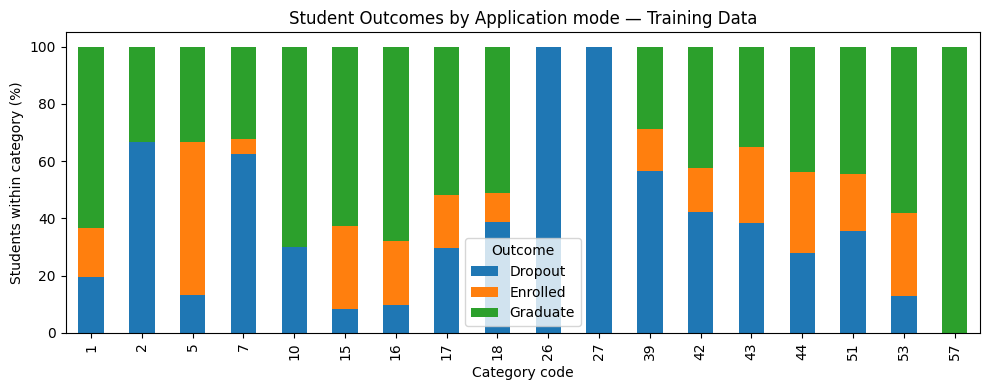


Tuition fees up to date
Target                   Students  Dropout (%)  Enrolled (%)  Graduate (%)
Tuition fees up to date                                                   
0                             419         86.9           8.1           5.0
1                            3120         24.8          19.3          56.0


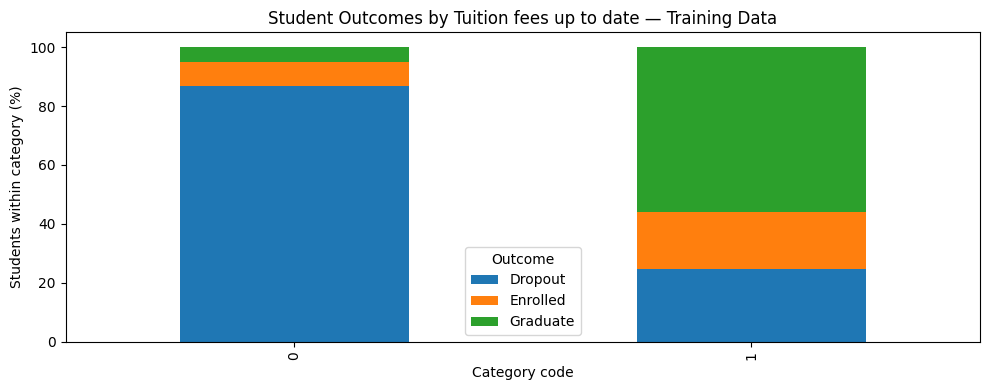

In [8]:
categorical_eda_cols = [
    "Course",
    "Application mode",
    "Tuition fees up to date"
]

for column in categorical_eda_cols:
    # Count outcomes within each category
    counts = pd.crosstab(X_train[column], y_train)

    # Convert counts into percentages within each category
    percentages = counts.div(counts.sum(axis=1), axis=0) * 100

    summary = percentages.round(1).add_suffix(" (%)")
    summary.insert(0, "Students", counts.sum(axis=1))

    print(f"\n{column}")
    print(summary)

    # Plot outcome percentages
    percentages.plot(
        kind="bar",
        stacked=True,
        figsize=(10, 4)
    )

    plt.title(f"Student Outcomes by {column} — Training Data")
    plt.xlabel("Category code")
    plt.ylabel("Students within category (%)")
    plt.legend(title="Outcome")
    plt.tight_layout()
    plt.show()

Define feature groups for preprocessing

In [12]:
# Categorical features to one-hot encode
categorical_cols = [
    "Marital status",
    "Application mode",
    "Application order",
    "Course",
    "Previous qualification",
    "Nationality",
    "Mother's qualification",
    "Father's qualification",
    "Mother's occupation",
    "Father's occupation"
]

# Binary indicators already represented as 0 or 1
binary_cols = [
    "Daytime/evening attendance",
    "Displaced",
    "Educational special needs",
    "Debtor",
    "Tuition fees up to date",
    "Gender",
    "Scholarship holder",
    "International"
]

# Remaining features are numeric measurements
numeric_cols = [
    column for column in X_train.columns
    if column not in categorical_cols + binary_cols
]

# Verify that every input is included
assert set(categorical_cols + binary_cols + numeric_cols) == set(X_train.columns)

print("Categorical features:", len(categorical_cols))
print("Binary features:", len(binary_cols))
print("Numeric features:", len(numeric_cols))

Categorical features: 10
Binary features: 8
Numeric features: 18


Correlation among the 18 numeric measurements

Numeric measurements included: 18


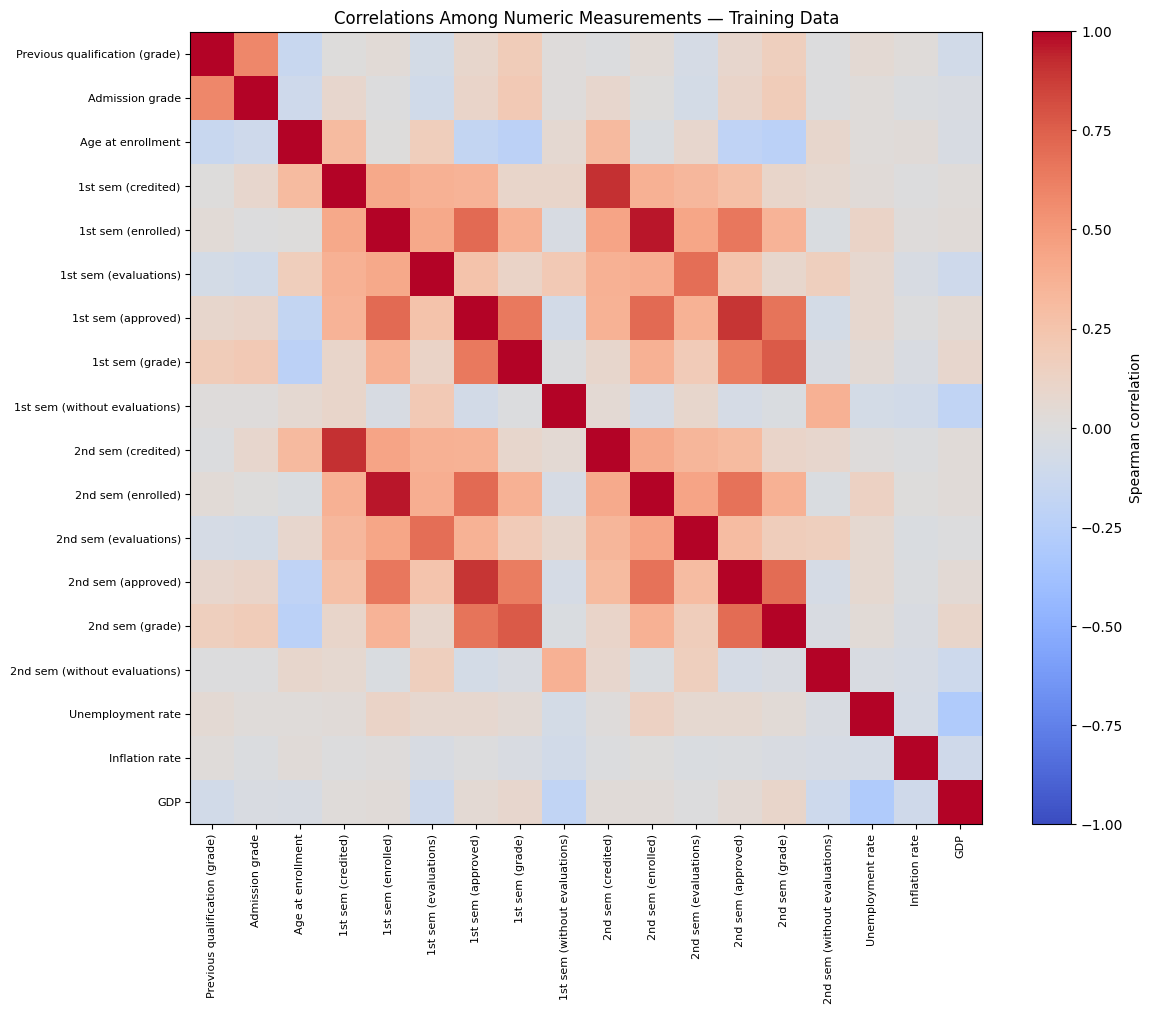

In [11]:
# Calculate correlations using training data only
correlation = X_train[numeric_cols].corr(method="spearman")

print("Numeric measurements included:", len(numeric_cols))

# Shorten labels for readability
labels = [
    column.replace("Curricular units ", "")
    for column in numeric_cols
]

# Plot the correlation matrix
plt.figure(figsize=(12, 10))

plt.imshow(
    correlation,
    cmap="coolwarm",
    vmin=-1,
    vmax=1
)

plt.xticks(range(len(labels)), labels, rotation=90, fontsize=8)
plt.yticks(range(len(labels)), labels, fontsize=8)

plt.colorbar(label="Spearman correlation")
plt.title("Correlations Among Numeric Measurements — Training Data")
plt.tight_layout()
plt.show()

##6. Define the preprocessing pipeline

In [14]:
# Prepare categorical features
categorical_transformer = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(
        handle_unknown="ignore",
        sparse_output=False
    ))
])

# Combine preprocessing for all three feature groups
preprocessor = ColumnTransformer([
    ("cat", categorical_transformer, categorical_cols),

    ("binary",
     SimpleImputer(strategy="most_frequent"),
     binary_cols),

    ("num",
     SimpleImputer(strategy="median"),
     numeric_cols)
])

print("Preprocessing pipeline defined.")

Preprocessing pipeline defined.


##7. Train the baseline Random Forest

In [15]:
# Combine preprocessing and Random Forest
rf_baseline = Pipeline([
    ("prep", preprocessor),
    ("rf", RandomForestClassifier(
        n_estimators=200,
        random_state=SEED,
        n_jobs=-1,
        oob_score=True
    ))
])

# Fit preprocessing and the model on training data
rf_baseline.fit(X_train, y_train)

# Display training diagnostics
print(
    "Training accuracy:",
    round(rf_baseline.score(X_train, y_train), 4)
)

print(
    "OOB accuracy:",
    round(rf_baseline.named_steps["rf"].oob_score_, 4)
)

Training accuracy: 1.0
OOB accuracy: 0.7742


##8. Evaluate the baseline using five-fold cross-validation

In [16]:
# Define five stratified folds
cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=SEED
)

# Evaluate several aspects of performance
scoring = {
    "accuracy": "accuracy",
    "macro_f1": "f1_macro",
    "balanced_accuracy": "balanced_accuracy"
}

baseline_cv = cross_validate(
    rf_baseline,
    X_train,
    y_train,
    cv=cv,
    scoring=scoring,
    return_train_score=True,
    n_jobs=1,
    error_score="raise"
)

print("Mean training accuracy:",
      round(baseline_cv["train_accuracy"].mean(), 4))

print("Mean CV accuracy:",
      round(baseline_cv["test_accuracy"].mean(), 4))

print("CV accuracy standard deviation:",
      round(baseline_cv["test_accuracy"].std(ddof=1), 4))

print("Mean CV macro-F1:",
      round(baseline_cv["test_macro_f1"].mean(), 4))

print("Mean CV balanced accuracy:",
      round(baseline_cv["test_balanced_accuracy"].mean(), 4))

Mean training accuracy: 1.0
Mean CV accuracy: 0.77
CV accuracy standard deviation: 0.0146
Mean CV macro-F1: 0.6724
Mean CV balanced accuracy: 0.6647


##9. Tune Random Forest using training cross-validation

In [17]:
# Settings to compare, including the original baseline settings
param_grid = {
    "rf__max_depth": [None, 10, 20],
    "rf__min_samples_leaf": [1, 2, 4],
    "rf__class_weight": [None, "balanced"]
}

# Compare settings using the same five training folds
rf_search = GridSearchCV(
    estimator=rf_baseline,
    param_grid=param_grid,
    scoring=scoring,
    refit="accuracy",
    cv=cv,
    return_train_score=True,
    n_jobs=1,
    error_score="raise",
    verbose=1
)

# Tune using training data only
rf_search.fit(X_train, y_train)

# The selected pipeline is already refitted on all training records
best_rf = rf_search.best_estimator_

print("Selected parameters:")
print(rf_search.best_params_)

print(
    "\nBest tuning-CV accuracy:",
    round(rf_search.best_score_, 4)
)

Fitting 5 folds for each of 18 candidates, totalling 90 fits
Selected parameters:
{'rf__class_weight': 'balanced', 'rf__max_depth': 20, 'rf__min_samples_leaf': 1}

Best tuning-CV accuracy: 0.7745


##10. Compare the baseline and selected Random Forest

In [18]:
best_index = rf_search.best_index_
search_results = rf_search.cv_results_

comparison = pd.DataFrame({
    "Model": ["Baseline RF", "Selected RF"],

    "Training accuracy": [
        rf_baseline.score(X_train, y_train),
        best_rf.score(X_train, y_train)
    ],

    "OOB accuracy": [
        rf_baseline.named_steps["rf"].oob_score_,
        best_rf.named_steps["rf"].oob_score_
    ],

    "CV accuracy": [
        baseline_cv["test_accuracy"].mean(),
        rf_search.best_score_
    ],

    "CV macro-F1": [
        baseline_cv["test_macro_f1"].mean(),
        search_results["mean_test_macro_f1"][best_index]
    ],

    "CV balanced accuracy": [
        baseline_cv["test_balanced_accuracy"].mean(),
        search_results["mean_test_balanced_accuracy"][best_index]
    ]
}).set_index("Model")

# Calculate the change in CV accuracy
accuracy_change = (
    comparison.loc["Selected RF", "CV accuracy"]
    - comparison.loc["Baseline RF", "CV accuracy"]
) * 100

print(f"CV accuracy change: {accuracy_change:+.2f} percentage points")

comparison.round(4)

CV accuracy change: +0.45 percentage points


,Training accuracy,OOB accuracy,CV accuracy,CV macro-F1,CV balanced accuracy
Model,,,,,
Baseline RF,1.0000,0.7742,0.7700,0.6724,0.6647
Selected RF,0.9963,0.7723,0.7745,0.6927,0.6810


## 11. Evaluate the selected model on the shared test benchmark

Accuracy             0.7661
Macro-F1             0.6885
Balanced accuracy    0.6782
Name: Selected Random Forest, dtype: float64

Classification report:
              precision    recall  f1-score   support

     Dropout     0.8008    0.7359    0.7670       284
    Enrolled     0.5514    0.3711    0.4436       159
    Graduate     0.7930    0.9276    0.8551       442

    accuracy                         0.7661       885
   macro avg     0.7151    0.6782    0.6885       885
weighted avg     0.7521    0.7661    0.7529       885



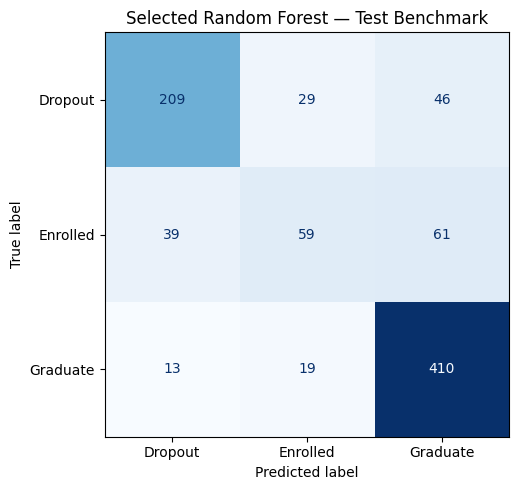

In [19]:
# Keep the CV-selected model as our final choice for this experiment
final_rf = best_rf

# Predict outcomes for the test students
y_pred_rf = final_rf.predict(X_test)

# Calculate benchmark metrics
test_metrics = pd.Series({
    "Accuracy": accuracy_score(y_test, y_pred_rf),
    "Macro-F1": f1_score(y_test, y_pred_rf, average="macro"),
    "Balanced accuracy": balanced_accuracy_score(y_test, y_pred_rf)
}, name="Selected Random Forest")

print(test_metrics.round(4))

# Show precision, recall and F1 for each class
class_order = ["Dropout", "Enrolled", "Graduate"]

print("\nClassification report:")
print(classification_report(
    y_test,
    y_pred_rf,
    labels=class_order,
    digits=4,
    zero_division=0
))

# Plot the confusion matrix
fig, ax = plt.subplots(figsize=(6, 5))

ConfusionMatrixDisplay.from_predictions(
    y_test,
    y_pred_rf,
    labels=class_order,
    cmap="Blues",
    ax=ax,
    colorbar=False
)

ax.set_title("Selected Random Forest — Test Benchmark")
fig.tight_layout()
plt.show()